<a href="https://colab.research.google.com/github/m1Febriansyah/244107020199-ML-12/blob/main/JS04_Praktikum01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

df = pd.read_csv('Iris.csv')

df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [ ]:
# Seleksi Fitur

X = df.iloc[:, 1:-1]
y = df.iloc[:, -1]

df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


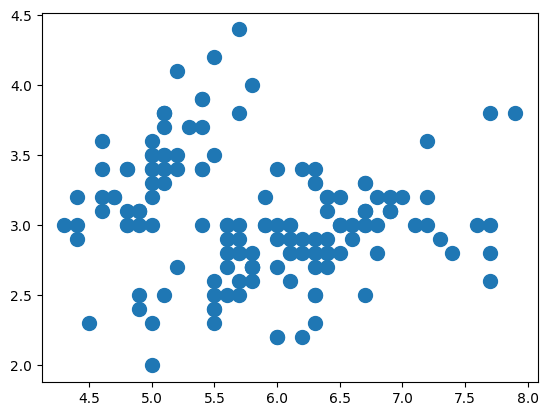

In [ ]:
# Plot Data
# Karena data 4 dimensi, maka akan kita coba
# plot cluster berdasarkan Sepal Length dan Sepal Width  saja

plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s = 100)

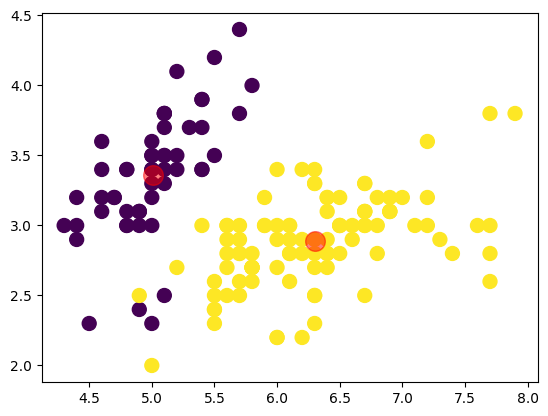

In [ ]:
# Buat Model KMeans
# Kali ini kita coba menggunakan k=2 - anggap saja kita tidak tahu jumlah label ada 3 :)

from sklearn.cluster import KMeans

# Inisiasi obyek KMeans
cl_kmeans = KMeans(n_clusters=2)

# Fit dan predict model
y_kmeans = cl_kmeans.fit_predict(X)

# Plot hasi cluster berdasarkan Sepal Length dan Sepal Width
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s = 100, c=y_kmeans)

# Plot centroid
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5)

In [ ]:
# Cek Nilai SSE
print(f'Nilai SSE: {cl_kmeans.inertia_}')

Nilai SSE: 152.36870647733915


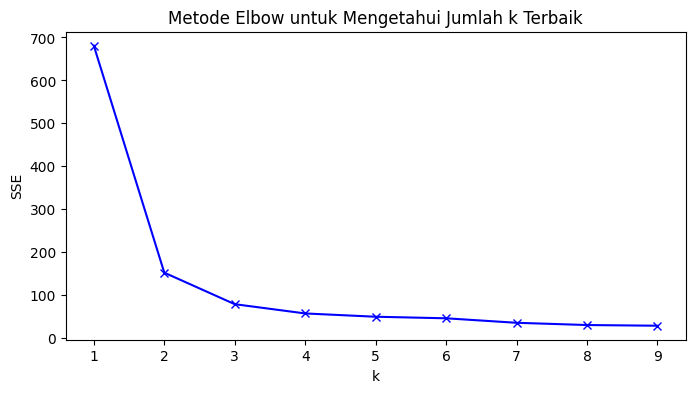

In [ ]:
# Implementasi Metode Elbow

# List nilai SSE
sse = []

# Cari k terbaik dari 1-10
K = range(1,10)

# Cek nilai SSE setiap k
for k in K:
 kmeanModel = KMeans(n_clusters=k)
 kmeanModel.fit(X)
 sse.append(kmeanModel.inertia_)


# Plotting the distortions
plt.figure(figsize=(8,4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Metode Elbow untuk Mengetahui Jumlah k Terbaik")
plt.show()

In [ ]:
# Cek Nilai SSE setiap k
for idx, sse_val in enumerate(sse, start=1):
    print(f'k={idx}; SSE={sse_val}')

k=1; SSE=680.8243999999996
k=2; SSE=152.36870647733915
k=3; SSE=78.94506582597728
k=4; SSE=57.371482025432464
k=5; SSE=49.72103090659343
k=6; SSE=46.08426101781214
k=7; SSE=35.632505984211896
k=8; SSE=30.398398841354723
k=9; SSE=28.795766831957586


In [9]:
# Persiapan data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('properti_multi_kota.csv')

# Imputasi missing value dengan median agar KMeans tidak error
for col in ['luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi']:
    df[col] = df[col].fillna(df[col].median())

# Filter outlier ekstrem (mengambil batas wajar hingga persentil ke-95) agar plot grafik terbaca jelas
df = df[
    (df['luas_m2'] > 0) & (df['luas_m2'] <= df['luas_m2'].quantile(0.95)) &
    (df['luas_bangunan'] > 0) & (df['luas_bangunan'] <= df['luas_bangunan'].quantile(0.95)) &
    (df['jumlah_kamar'] > 0) & (df['jumlah_kamar'] <= 15) &
    (df['jumlah_kamar_mandi'] > 0) & (df['jumlah_kamar_mandi'] <= 15)
].copy()

df.head()

,sumber,lokasi,luas_m2,luas_bangunan,jumlah_kamar,jumlah_kamar_mandi,usia_bangunan,harga
0,uas-properti/Jabodetabek,Tangerang,30.0,63.0,3.0,3.0,33.0,2.037543e+08
1,uas-properti/Jabodetabek,Bekasi,122.0,63.0,5.0,4.0,19.0,1.058032e+09
2,uas-properti/Jabodetabek,Bekasi,142.8,63.0,1.0,1.0,9.0,1.335793e+09
3,uas-properti/Jabodetabek,Bekasi,152.6,63.0,4.0,3.0,6.0,1.613771e+09
4,uas-properti/Jabodetabek,Depok,61.2,63.0,1.0,1.0,9.0,5.221562e+08


In [10]:
# Seleksi Fitur (4 fitur numerik properti sebagai X, dan harga sebagai y)
X = df[['luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi']]
y = df['harga']

X.head()

,luas_m2,luas_bangunan,jumlah_kamar,jumlah_kamar_mandi
0,30.0,63.0,3.0,3.0
1,122.0,63.0,5.0,4.0
2,142.8,63.0,1.0,1.0
3,152.6,63.0,4.0,3.0
4,61.2,63.0,1.0,1.0


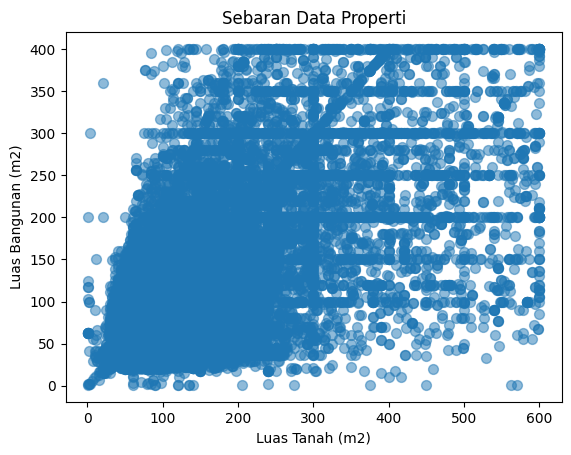

In [11]:
# Plot Data
# Plot sebaran berdasarkan Luas Tanah (luas_m2) dan Luas Bangunan (luas_bangunan)
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=50, alpha=0.5)
plt.xlabel('Luas Tanah (m2)')
plt.ylabel('Luas Bangunan (m2)')
plt.title('Sebaran Data Properti')
plt.show()

In [12]:
# Buat Model KMeans dengan k=2
cl_kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)

# Fit dan predict model
y_kmeans = cl_kmeans.fit_predict(X)

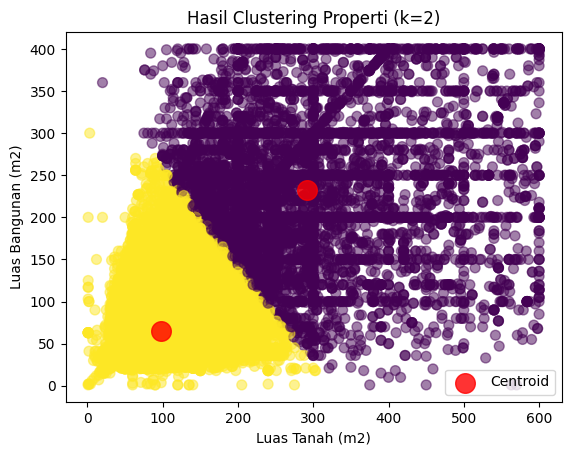

Nilai SSE: 276960574.6292596


In [14]:
# Plot hasil cluster berdasarkan Luas Tanah dan Luas Bangunan
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=50, c=y_kmeans, alpha=0.5)
plt.xlabel('Luas Tanah (m2)')
plt.ylabel('Luas Bangunan (m2)')
plt.title('Hasil Clustering Properti (k=2)')

# Plot centroid
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.8, label='Centroid')
plt.legend()
plt.show()

# Cek Nilai SSE
print(f'Nilai SSE: {cl_kmeans.inertia_}')

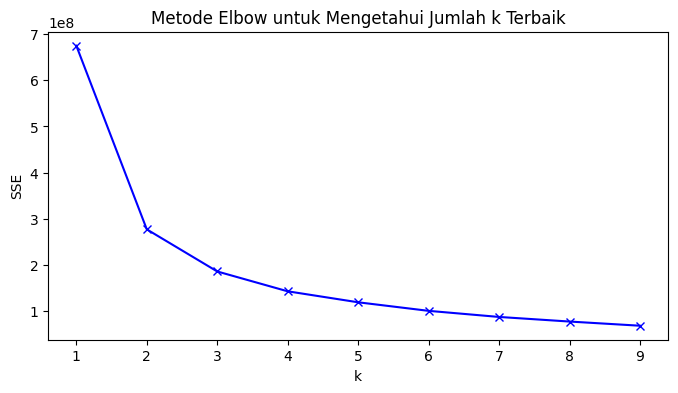

In [15]:
# Implementasi Metode Elbow
sse = []
K = range(1, 10)

for k in K:
    kmeanModel = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeanModel.fit(X)
    sse.append(kmeanModel.inertia_)

# Plotting the distortions
plt.figure(figsize=(8, 4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Metode Elbow untuk Mengetahui Jumlah k Terbaik")
plt.show()

In [16]:
# Cek Nilai SSE setiap k
for idx, sse_val in enumerate(sse, start=1):
    print(f'k={idx}; SSE={sse_val}')

k=1; SSE=675039955.0365235
k=2; SSE=276960574.6292596
k=3; SSE=185669437.5115669
k=4; SSE=142657731.71226385
k=5; SSE=118843962.31858239
k=6; SSE=100304687.10266753
k=7; SSE=87087590.50382274
k=8; SSE=77109960.06256343
k=9; SSE=68060117.22989942
